## future changes robustness

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [3]:
from scipy import stats

In [4]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [6]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [7]:
from functions import preproc_funcs as funcs

In [8]:
from functions import xr_lowess

#### load cmip6 data and data from access lens

In [16]:
ts_cmip_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp5.nc').ts.sel(time=slice('1900', '2100')).load()
ts_cmip_ssp3 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp3.nc').ts.sel(time=slice('1900', '2100')).load()
ts_cmip_ssp2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp2.nc').ts.sel(time=slice('1900', '2100')).load()
ts_cmip_ssp1 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp1.nc').ts.sel(time=slice('1900', '2100')).load()

pr_cmip_ssp5 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/pr_ssp5.nc').pr.sel(time=slice('1900', '2100'))*86400*30).load()
pr_cmip_ssp3 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/pr_ssp3.nc').pr.sel(time=slice('1900', '2100'))*86400*30).load()
pr_cmip_ssp2 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/pr_ssp2.nc').pr.sel(time=slice('1900', '2100'))*86400*30).load()
pr_cmip_ssp1 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/pr_ssp1.nc').pr.sel(time=slice('1900', '2100'))*86400*30).load()

In [10]:
ts_access_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_ts.nc').ts.sel(time=slice('1900', '2100')).load()
ts_access_ssp3 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp3_ts.nc').ts.sel(time=slice('1900', '2100')).load()
ts_access_ssp2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp2_ts.nc').ts.sel(time=slice('1900', '2100')).load()
ts_access_ssp1 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_ts.nc').ts.sel(time=slice('1900', '2100')).load()

pr_access_ssp5 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_pr.nc').pr.sel(time=slice('1900', '2100'))*86400*30).load()
pr_access_ssp3 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp3_pr.nc').pr.sel(time=slice('1900', '2100'))*86400*30).load()
pr_access_ssp2 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp2_pr.nc').pr.sel(time=slice('1900', '2100'))*86400*30).load()
pr_access_ssp1 = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_pr.nc').pr.sel(time=slice('1900', '2100'))*86400*30).load()

In [11]:
# ts_access_stable = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/access_stable.nc').ts
# pr_access_stable = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/access_stable_pr.nc').pr*86400*30)

In [11]:
weights_model = np.cos(np.deg2rad(ts_cmip_ssp5.lat))

ts_cmip_ssp5_anom = funcs.calc_anom(ts_cmip_ssp5, ts_cmip_ssp5.sel(time = slice('1960', '1990')))
nino34_ssp5_cmip = funcs.detrend_separate_check(ts_cmip_ssp5_anom.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), dim='time', period=15)

In [12]:
ts_access_ssp5_anom = funcs.calc_anom(ts_access_ssp5, ts_access_ssp5.sel(time = slice('1960', '1990')))
nino34_access_ssp5 = funcs.detrend_separate_check(ts_access_ssp5_anom.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), dim='time', period=15)

In [13]:
# ts_access_stable_anom = funcs.calc_anom(ts_access_stable, ts_access_ssp5.sel(model = 'ACCESS-ESM1-5_r10i1p1f1', time = slice('1960', '1990')))
# tempporary_reg_mean = ts_access_ssp5_anom.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon'))
# nino34_access_stable =  tempporary_reg_mean - tempporary_reg_mean.rolling(time=15).mean('time')

In [14]:
import regionmask

In [16]:
land_mask_model = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_cmip_ssp5)
ar6_mask_model = regionmask.defined_regions.ar6.land.mask_3D(land_mask_model)

reg_anom_cmip = pr_cmip_ssp5.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon'))
reg_anom_access = pr_access_ssp5.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon'))

In [17]:
reg_anom_access_stable = pr_access_stable.where(ar6_mask_model.isel(region=41)).weighted(weights_model).mean(('lat', 'lon'))

In [18]:
reg_det_cmip = funcs.detrend_separate_check(reg_anom_cmip, dim='time', period=15)
reg_det_access = funcs.detrend_separate_check(reg_anom_access, dim='time', period=15)

reg_std_cmip = reg_det_cmip/reg_det_cmip.std('time')
reg_std_access = reg_det_access/reg_det_access.std('time')

In [19]:
reg_det_access_stable = reg_anom_access_stable - reg_anom_access_stable.rolling(time=15).mean('time')
reg_std_access_stable = reg_det_access_stable/reg_det_access_stable.std('time')

In [20]:
reg_std_cmip['model'] = nino34_ssp5_cmip.drop_sel(model='KIOST-ESM')['model']
reg_std_access['model'] = nino34_access_ssp5['model']

In [21]:
regr_cmip_20c = funcs.get_regr(nino34_ssp5_cmip.sel(time = slice('1900', '2000')).drop_sel(model='KIOST-ESM'), reg_std_cmip.sel(time = slice('1900', '2000')), dim='time')
regr_cmip_21c = funcs.get_regr(nino34_ssp5_cmip.sel(time = slice('2000', '2100')).drop_sel(model='KIOST-ESM'), reg_std_cmip.sel(time = slice('2000', '2100')), dim='time')

In [22]:
regr_access_20c = funcs.get_regr(nino34_access_ssp5.sel(time = slice('1900', '2000')), reg_std_access.sel(time = slice('1900', '2000')), dim='time')
regr_access_21c = funcs.get_regr(nino34_access_ssp5.sel(time = slice('2000', '2100')), reg_std_access.sel(time = slice('2000', '2100')), dim='time')

In [24]:
# loading the observed ones
reg_std_obs = xr.open_dataarray('./data/eaus_obs.nc')
nino34_obs = xr.open_dataarray('./data/nino34_obs.nc')

In [26]:
regr_obs = funcs.get_regr_1d(nino34_obs.sel(time = slice('1900', '2000')), reg_std_obs.sel(time = slice('1900', '2000')))
regr_obs

-0.8299097142736716

In [27]:
import seaborn as sns

Text(0.5, 1.0, '100 years internal variability')

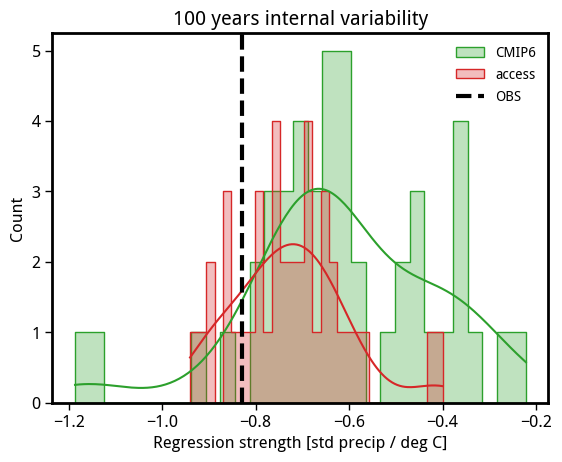

In [28]:
sns.histplot(regr_cmip_20c, element='step', kde=True, bins=31, alpha=0.3, color='tab:green', label='CMIP6')
sns.histplot(regr_access_20c, element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='access')
plt.axvline(regr_obs, color='k', lw=3.0, ls='--', label='OBS')
# sns.histplot(, element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='access')
# sns.histplot(, element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='canesm')
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [std precip / deg C]')
plt.title('100 years internal variability')

Text(0.5, 1.0, '100 years internal variability')

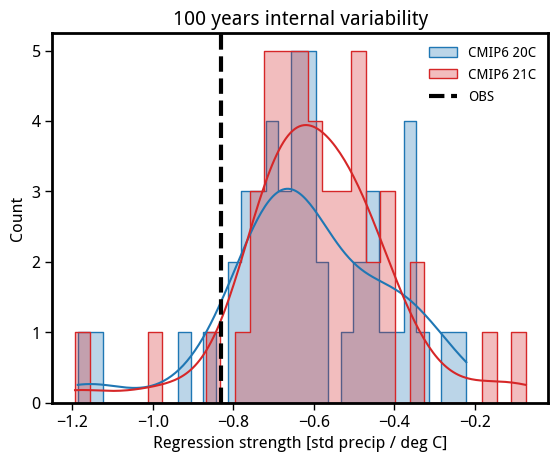

In [30]:
sns.histplot(regr_cmip_20c, element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='CMIP6 20C')
sns.histplot(regr_cmip_21c, element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='CMIP6 21C')
plt.axvline(regr_obs, color='k', lw=3.0, ls='--', label='OBS')
# sns.histplot(, element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='access')
# sns.histplot(, element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='canesm')
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [std precip / deg C]')
plt.title('100 years internal variability')

Text(0.5, 1.0, '100 years internal variability')

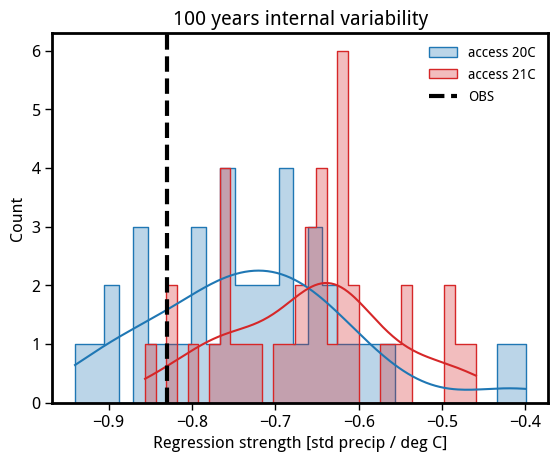

In [31]:
sns.histplot(regr_access_20c, element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='access 20C')
sns.histplot(regr_access_21c, element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='access 21C')
plt.axvline(regr_obs, color='k', lw=3.0, ls='--', label='OBS')
# sns.histplot(, element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='access')
# sns.histplot(, element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='canesm')
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [std precip / deg C]')
plt.title('100 years internal variability')

In [38]:
stable_levels = []
regr_arr = []
for i in range(0,10):
    regr = reg_det_access_stable.isel(model=0).isel(time = slice(0,100))

<xarray.DataArray 'pr' (time: 987)>
array([-2.03177259e+01,  2.19750391e+01,  1.51597814e+00, -4.06988679e+00,
        3.61041190e+01,  2.24298854e+01,  7.23167355e+00, -5.24621412e+00,
        7.29189801e+00, -1.15467714e+01,  1.24599823e+01, -4.76888554e+00,
       -1.85360562e+01, -5.14602987e+00,  3.57650550e+01, -1.81802027e+01,
       -3.30324049e+01,  3.76242020e+00, -2.29730761e+00, -9.56463467e+00,
       -2.80330212e+00, -2.54708510e+01, -1.21626103e+01,  3.55386800e+00,
        3.41637717e+00, -2.15357060e+01,  1.75027121e+01, -9.67802356e+00,
        1.07164223e+01, -1.49014991e+01,  3.26331713e+01,  1.07916131e+01,
       -4.45936817e-01, -1.18587046e+01, -1.25734842e+00,  2.91202581e+00,
        1.13810704e+01, -6.25810590e+00, -1.92358999e+01, -1.22889091e+01,
       -1.04561395e+01, -1.16553220e+00,  1.53111541e+01, -1.18027747e+01,
       -3.95989475e+00,  3.42636618e+01, -9.58639914e+00, -7.35911474e+00,
        1.30610435e+01,  5.98241357e+00, -3.25716240e-01, -6.10568310e+00,
       -1.97216330e+00,  2.36785048e+01,  1.16153541e+01,  4.43661928e+00,
        1.14722101e+01,  7.09671571e+00,  1.88710533e+00, -1.52907065e+01,
       -1.18890514e+01, -1.67126734e+01, -2.18609814e+01, -1.23995504e+01,
        8.39835501e+00,  1.56459355e+01,  1.60653157e+01, -1.21668608e+01,
        2.71613023e+00,  3.52730570e+00,  3.59942388e+00, -1.19288265e+00,
        4.87396870e+00,  2.17191223e+01, -1.61971140e+00, -3.05456360e+00,
       -1.50049712e+01, -5.96641441e+00, -4.34249653e+00,  2.76793049e-01,
...
        2.34581388e+01, -1.25477077e+01,  4.50469981e+00,  3.02565258e+01,
       -2.86051868e+00,  1.95806695e+01,  3.32975853e+01, -1.59866296e+01,
       -2.21032883e+01, -2.17294984e+01, -7.99822908e+00,  9.01298233e+00,
       -1.90600703e+01, -1.61338530e+01,  1.32693989e+00, -5.15384554e+00,
       -1.78968136e+00,  2.51028439e+00,  1.00821093e+01,  5.43808053e+00,
        3.53733892e+00, -1.38832263e+01, -8.77760599e+00, -2.25659859e-01,
       -1.32474226e+00,  2.37283500e+01,  3.67755021e+01,  5.70363118e+00,
       -4.16086412e+00, -2.63454204e+01,  1.54566616e+01,  5.82181383e+00,
        1.91887560e+01,  1.32580568e+01,  8.13389335e+00, -2.81864689e+01,
       -1.86563202e-01,  2.58170451e+00,  2.66413082e+00,  5.74724176e-02,
       -3.26998197e+00,  6.33644402e+00, -1.07433374e+01, -5.99199877e-01,
        3.21689289e+00, -1.75787863e+01, -2.19342940e-01, -3.26016811e+00,
       -8.91865141e+00,  1.22057586e+01, -1.89453722e+01,  2.12965704e+00,
        5.13883523e+00,  2.55700870e+01,  1.46476571e-01, -2.57580931e+01,
       -1.06699513e+01, -1.12015772e+01,  7.14921749e+00,  1.72731142e+01,
       -3.38712208e+00,  1.95926129e+01,  6.13636946e+00,  2.00446641e+01,
       -4.50730020e-02,  2.44326791e+01,  8.90836086e+00,  5.30196474e+00,
       -2.08933844e+01,  6.36270276e+00,  9.34972050e+00, -2.41926166e+01,
       -2.76964129e+01,  1.73805540e+01, -2.42533507e+01,  1.17528636e+01,
        4.25503508e+00,  1.32544049e+01, -1.25149180e+00])
Coordinates:
  * time     (time) object 2063-06-01 00:00:00 ... 3049-06-01 00:00:00
    model    <U5 'B2050'
    region   int64 41
    abbrevs  <U4 'EAU'
    names    <U22 'E.Australia'